In [8]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans


# 1. Load the dataset.
df = pd.read_csv("/content/drive/MyDrive/sales_data_sample.csv",encoding="latin1")

In [9]:
# 2. Aggregate sales information customer-wise.
customer_data = df.groupby("CUSTOMERNAME").agg({
    "SALES": "sum",
    "QUANTITYORDERED": "sum",
    "PRICEEACH": "mean"
}).reset_index()

In [10]:
# 3. Select features for clustering.
X = customer_data[
    ["SALES", "QUANTITYORDERED", "PRICEEACH"]
]

In [11]:
# 4. Normalize the data.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [12]:
# 5. Apply the Elbow Method for K values from 1 to 10.
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

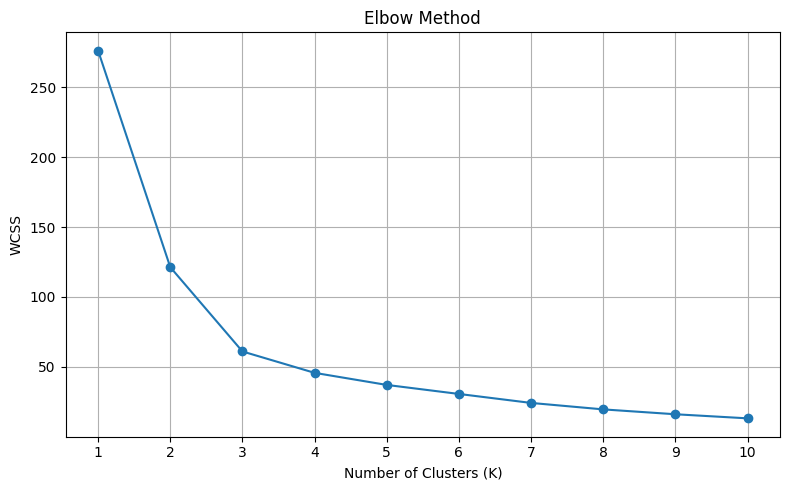

In [13]:
# 6. Plot K against WCSS to identify the elbow point.
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)
plt.tight_layout()
plt.show()


In [14]:
# 7. Train the final model.
# The practical's illustrative output shows 3 clusters.
# Check the elbow graph and change n_clusters if another K is more suitable.
optimal_k = 3

final_kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

customer_data["Cluster"] = final_kmeans.fit_predict(X_scaled)

In [15]:
# 8. Display the number of customers in each cluster.
print("Cluster Counts:")
print(customer_data["Cluster"].value_counts().sort_index())

Cluster Counts:
Cluster
0    42
1     2
2    48
Name: count, dtype: int64
